### 1. Data reading

In [93]:
import polars as pl

dfs = []
for month in range(1, 13):
    df = pl.scan_parquet(f"./data/{month}.parquet")
    df = df.with_columns(
        pl.col("tpep_pickup_datetime").dt.cast_time_unit("ms"),
        pl.col("tpep_dropoff_datetime").dt.cast_time_unit("ms"),
    ).filter(
        (pl.col("tpep_pickup_datetime") >= pl.datetime(2024, 1, 1))
        & (pl.col("tpep_pickup_datetime") < pl.datetime(2025, 1, 1))
        & (pl.col("tpep_dropoff_datetime") <= pl.datetime(2025, 1, 1))
    )
    dfs.append(df)

df = pl.concat(dfs)

In [94]:
taxi_df = pl.scan_csv("./data/taxi_zone_lookup.csv")

In [95]:
df = df.with_columns(
    pl.col("VendorID").cast(pl.UInt8),
    pl.col("passenger_count").cast(pl.UInt8),
    pl.col("RatecodeID").cast(pl.UInt8),
    pl.col("store_and_fwd_flag").cast(pl.Categorical), # encodes repeated strings
    pl.col("PULocationID").cast(pl.UInt16),
    pl.col("DOLocationID").cast(pl.UInt16),
    pl.col("payment_type").cast(pl.UInt8),
)

df.collect_schema()



Schema([('VendorID', UInt8),
        ('tpep_pickup_datetime', Datetime(time_unit='ms', time_zone=None)),
        ('tpep_dropoff_datetime', Datetime(time_unit='ms', time_zone=None)),
        ('passenger_count', UInt8),
        ('trip_distance', Float64),
        ('RatecodeID', UInt8),
        ('store_and_fwd_flag', Categorical(ordering='physical')),
        ('PULocationID', UInt16),
        ('DOLocationID', UInt16),
        ('payment_type', UInt8),
        ('fare_amount', Float64),
        ('extra', Float64),
        ('mta_tax', Float64),
        ('tip_amount', Float64),
        ('tolls_amount', Float64),
        ('improvement_surcharge', Float64),
        ('total_amount', Float64),
        ('congestion_surcharge', Float64),
        ('Airport_fee', Float64)])

In [96]:
taxi_df.collect().describe()

statistic,LocationID,Borough,Zone,service_zone
str,f64,str,str,str
"""count""",265.0,"""265""","""265""","""265"""
"""null_count""",0.0,"""0""","""0""","""0"""
"""mean""",133.0,null,null,null
"""std""",76.643112,null,null,null
"""min""",1.0,"""Bronx""","""Allerton/Pelham Gardens""","""Airports"""
"""25%""",67.0,null,null,null
"""50%""",133.0,null,null,null
"""75%""",199.0,null,null,null
"""max""",265.0,"""Unknown""","""Yorkville West""","""Yellow Zone"""


In [97]:
taxi_df = taxi_df.with_columns(
    pl.col("LocationID").cast(pl.UInt16),
)

taxi_df.collect_schema()


Schema([('LocationID', UInt16),
        ('Borough', String),
        ('Zone', String),
        ('service_zone', String)])

### 2. Data cleaning and filtering 

In [98]:
# fill NULL values in passengers_count with 1

df = df.with_columns(
    pl.col("passenger_count").fill_null(1)
)

In [99]:
# remove rides with zero passengers

df = df.filter(pl.col("passenger_count") > 0)

In [100]:
# if a ride has over 6 passengers, replace the value with 6

df = df.with_columns(
    pl.col("passenger_count").clip(1, 6) # after previous steps the min value is 1
)

In [101]:
# remove rides lasting over 2 hours

df = df.filter(
    (pl.col("tpep_dropoff_datetime") - pl.col("tpep_pickup_datetime")) <= pl.duration(hours=2)
)

In [102]:
#  in all money-related columns, replace values with absolute value to fix negative amounts

df = df.with_columns(
    pl.col("fare_amount").abs(),
    pl.col("extra").abs(),
    pl.col("mta_tax").abs(),
    pl.col("tip_amount").abs(),
    pl.col("tolls_amount").abs(),
    pl.col("improvement_surcharge").abs(),
    pl.col("total_amount").abs(),
    pl.col("congestion_surcharge").abs(),
    pl.col("Airport_fee").abs(),
)


In [103]:
# remove rides with over 1000 dollars in any money-related column

df = df.filter(
    (pl.col("fare_amount") <= 1000)
    & (pl.col("extra") <= 1000)
    & (pl.col("mta_tax") <= 1000)
    & (pl.col("tip_amount") <= 1000)
    & (pl.col("tolls_amount") <= 1000)
    & (pl.col("improvement_surcharge") <= 1000)
    & (pl.col("total_amount") <= 1000)
    & (pl.col("congestion_surcharge") <= 1000)
    & (pl.col("Airport_fee") <= 1000)
)

In [104]:
# remove rows with values of RatecodeID or VendorID missing or outside those defined in the data dictionary

df = df.filter(
    (pl.col("RatecodeID").is_in([1, 2, 3, 4, 5, 6, 99]))
    & (pl.col("VendorID").is_in([1, 2, 6, 7]))
)


### 3. Data transformation

In [105]:
# combine payment type values for "No charge", "Dispute", "Unknown" and "Voided trip" into one type,
# so we have only credit card, cash, or other

df = df.with_columns(
    pl.when(pl.col("payment_type").is_in([0, 3, 4, 5, 6]))
    .then(pl.lit(3))
    .otherwise(pl.col("payment_type"))
    .alias("payment_type")
)


In [106]:
# replace PULocationID and DOLocationID with borough names by joining taxi zone lookup and removing unnecessary columns

df = (
    df.join(
        taxi_df.select("LocationID", pl.col("Borough").alias("PU_Borough")),
        left_on="PULocationID",
        right_on="LocationID",
        how="left",
    )
    .join(
        taxi_df.select("LocationID", pl.col("Borough").alias("DO_Borough")),
        left_on="DOLocationID",
        right_on="LocationID",
        how="left",
    )
    .drop("PULocationID", "DOLocationID")
)


In [107]:
df.limit(10).collect(streaming=True)


/tmp/ipykernel_185772/3791766996.py:1: DeprecationWarning: The old streaming engine is being deprecated and will soon be replaced by the new streaming engine. Starting Polars version 1.23.0 and until the new streaming engine is released, the old streaming engine may become less usable. For people who rely on the old streaming engine, it is suggested to pin your version to before 1.23.0.

More information on the new streaming engine: https://github.com/pola-rs/polars/issues/20947
  df.limit(10).collect(streaming=True)


VendorID,tpep_pickup_datetime,tpep_dropoff_datetime,passenger_count,trip_distance,RatecodeID,store_and_fwd_flag,payment_type,fare_amount,extra,mta_tax,tip_amount,tolls_amount,improvement_surcharge,total_amount,congestion_surcharge,Airport_fee,PU_Borough,DO_Borough
u8,datetime[ms],datetime[ms],u8,f64,u8,cat,u8,f64,f64,f64,f64,f64,f64,f64,f64,f64,str,str
2,2024-01-01 00:57:55,2024-01-01 01:17:43,1,1.72,1,"""N""",2,17.7,1.0,0.5,0.0,0.0,1.0,22.7,2.5,0.0,"""Manhattan""","""Manhattan"""
1,2024-01-01 00:03:00,2024-01-01 00:09:36,1,1.8,1,"""N""",1,10.0,3.5,0.5,3.75,0.0,1.0,18.75,2.5,0.0,"""Manhattan""","""Manhattan"""
1,2024-01-01 00:17:06,2024-01-01 00:35:01,1,4.7,1,"""N""",1,23.3,3.5,0.5,3.0,0.0,1.0,31.3,2.5,0.0,"""Manhattan""","""Manhattan"""
1,2024-01-01 00:36:38,2024-01-01 00:44:56,1,1.4,1,"""N""",1,10.0,3.5,0.5,2.0,0.0,1.0,17.0,2.5,0.0,"""Manhattan""","""Manhattan"""
1,2024-01-01 00:46:51,2024-01-01 00:52:57,1,0.8,1,"""N""",1,7.9,3.5,0.5,3.2,0.0,1.0,16.1,2.5,0.0,"""Manhattan""","""Manhattan"""
1,2024-01-01 00:54:08,2024-01-01 01:26:31,1,4.7,1,"""N""",1,29.6,3.5,0.5,6.9,0.0,1.0,41.5,2.5,0.0,"""Manhattan""","""Manhattan"""
2,2024-01-01 00:49:44,2024-01-01 01:15:47,2,10.82,1,"""N""",1,45.7,6.0,0.5,10.0,0.0,1.0,64.95,0.0,1.75,"""Queens""","""Brooklyn"""
2,2024-01-01 00:26:01,2024-01-01 00:54:12,1,5.44,1,"""N""",2,31.0,1.0,0.5,0.0,0.0,1.0,36.0,2.5,0.0,"""Manhattan""","""Manhattan"""
2,2024-01-01 00:28:08,2024-01-01 00:29:16,1,0.04,1,"""N""",2,3.0,1.0,0.5,0.0,0.0,1.0,8.0,2.5,0.0,"""Manhattan""","""Manhattan"""


In [108]:
# add boolean variable is_airport_ride, true if there is non-zero airport fee

df = df.with_columns(
    (pl.col("Airport_fee") > 0).alias("is_airport_ride")
)

In [109]:
# add boolean variable is_rush_hour, rush hours are defined as 6:30–9:30 and 15:30-20:00 during weekdays

is_weekday = pl.col("tpep_pickup_datetime").dt.weekday().is_between(1, 5)


# I assumed that we should check intersection with rush hours
is_early_rush_hour = (
    (pl.col("tpep_dropoff_datetime").dt.time() >= pl.time(6, 30))
    & (pl.col("tpep_pickup_datetime").dt.time() < pl.time(9, 30))
    & is_weekday
)

is_late_rush_hour = (
    (pl.col("tpep_dropoff_datetime").dt.time() >= pl.time(15, 30))
    & (pl.col("tpep_pickup_datetime").dt.time() < pl.time(20, 0))
    & is_weekday
)

df = df.with_columns(
    (is_early_rush_hour | is_late_rush_hour).alias("is_rush_hour")
)


In [110]:
df.filter(pl.col("is_rush_hour")).limit(10).collect(streaming=True)

/tmp/ipykernel_185772/4189696310.py:1: DeprecationWarning: The old streaming engine is being deprecated and will soon be replaced by the new streaming engine. Starting Polars version 1.23.0 and until the new streaming engine is released, the old streaming engine may become less usable. For people who rely on the old streaming engine, it is suggested to pin your version to before 1.23.0.

More information on the new streaming engine: https://github.com/pola-rs/polars/issues/20947
  df.filter(pl.col("is_rush_hour")).limit(10).collect(streaming=True)


VendorID,tpep_pickup_datetime,tpep_dropoff_datetime,passenger_count,trip_distance,RatecodeID,store_and_fwd_flag,payment_type,fare_amount,extra,mta_tax,tip_amount,tolls_amount,improvement_surcharge,total_amount,congestion_surcharge,Airport_fee,PU_Borough,DO_Borough,is_airport_ride,is_rush_hour
u8,datetime[ms],datetime[ms],u8,f64,u8,cat,u8,f64,f64,f64,f64,f64,f64,f64,f64,f64,str,str,bool,bool
2,2024-01-01 05:58:38,2024-01-01 06:30:25,1,20.64,2,"""N""",2,70.0,0.0,0.5,0.0,6.94,1.0,80.19,0.0,1.75,"""Queens""","""Manhattan""",true,true
1,2024-01-01 05:59:08,2024-01-01 06:33:26,1,16.1,99,"""N""",1,56.5,0.0,0.5,0.0,6.94,1.0,64.94,0.0,0.0,"""Bronx""","""Brooklyn""",false,true
2,2024-01-01 05:41:16,2024-01-01 06:41:21,1,14.52,1,"""N""",2,71.6,1.0,0.5,0.0,0.0,1.0,76.6,2.5,0.0,"""Manhattan""","""Manhattan""",false,true
2,2024-01-01 05:54:42,2024-01-01 06:33:59,2,17.69,2,"""N""",1,70.0,0.0,0.5,16.19,6.94,1.0,97.13,2.5,0.0,"""Manhattan""","""Queens""",false,true
2,2024-01-01 05:56:18,2024-01-01 06:40:08,2,28.43,3,"""N""",1,127.3,1.0,0.0,29.85,19.95,1.0,179.1,0.0,0.0,"""Manhattan""","""EWR""",false,true
2,2024-01-01 05:30:03,2024-01-01 06:31:03,2,30.2,1,"""N""",2,119.2,1.0,0.5,0.0,0.0,1.0,124.2,2.5,0.0,"""Manhattan""","""Brooklyn""",false,true
2,2024-01-01 05:57:23,2024-01-01 06:32:49,1,23.73,2,"""N""",1,70.0,0.0,0.5,15.15,0.0,1.0,90.9,2.5,1.75,"""Queens""","""Brooklyn""",true,true
1,2024-01-01 05:58:04,2024-01-01 06:59:47,1,19.8,99,"""N""",1,58.5,0.0,0.5,0.0,6.94,1.0,66.94,0.0,0.0,"""Bronx""","""Brooklyn""",false,true
2,2024-01-01 05:55:31,2024-01-01 06:30:17,1,19.51,2,"""N""",1,70.0,0.0,0.5,16.54,6.94,1.0,99.23,2.5,1.75,"""Queens""","""Manhattan""",true,true


### 4. Feature extraction 

In [111]:
# apply dummy encoding to features:\
# payment type,
# pickup borough,
# dropoff borough

df = (
    df.collect().to_dummies(["payment_type", "PU_Borough", "DO_Borough"]).lazy()
)


In [112]:
df.limit(10).collect(streaming=True)

/tmp/ipykernel_185772/1880006223.py:1: DeprecationWarning: The old streaming engine is being deprecated and will soon be replaced by the new streaming engine. Starting Polars version 1.23.0 and until the new streaming engine is released, the old streaming engine may become less usable. For people who rely on the old streaming engine, it is suggested to pin your version to before 1.23.0.

More information on the new streaming engine: https://github.com/pola-rs/polars/issues/20947
  df.limit(10).collect(streaming=True)


VendorID,tpep_pickup_datetime,tpep_dropoff_datetime,passenger_count,trip_distance,RatecodeID,store_and_fwd_flag,payment_type_1,payment_type_2,payment_type_3,fare_amount,extra,mta_tax,tip_amount,tolls_amount,improvement_surcharge,total_amount,congestion_surcharge,Airport_fee,PU_Borough_Bronx,PU_Borough_Brooklyn,PU_Borough_EWR,PU_Borough_Manhattan,PU_Borough_N/A,PU_Borough_Queens,PU_Borough_Staten Island,PU_Borough_Unknown,DO_Borough_Bronx,DO_Borough_Brooklyn,DO_Borough_EWR,DO_Borough_Manhattan,DO_Borough_N/A,DO_Borough_Queens,DO_Borough_Staten Island,DO_Borough_Unknown,is_airport_ride,is_rush_hour
u8,datetime[ms],datetime[ms],u8,f64,u8,cat,u8,u8,u8,f64,f64,f64,f64,f64,f64,f64,f64,f64,u8,u8,u8,u8,u8,u8,u8,u8,u8,u8,u8,u8,u8,u8,u8,u8,bool,bool
2,2024-01-01 00:57:55,2024-01-01 01:17:43,1,1.72,1,"""N""",0,1,0,17.7,1.0,0.5,0.0,0.0,1.0,22.7,2.5,0.0,0,0,0,1,0,0,0,0,0,0,0,1,0,0,0,0,false,false
1,2024-01-01 00:03:00,2024-01-01 00:09:36,1,1.8,1,"""N""",1,0,0,10.0,3.5,0.5,3.75,0.0,1.0,18.75,2.5,0.0,0,0,0,1,0,0,0,0,0,0,0,1,0,0,0,0,false,false
1,2024-01-01 00:17:06,2024-01-01 00:35:01,1,4.7,1,"""N""",1,0,0,23.3,3.5,0.5,3.0,0.0,1.0,31.3,2.5,0.0,0,0,0,1,0,0,0,0,0,0,0,1,0,0,0,0,false,false
1,2024-01-01 00:36:38,2024-01-01 00:44:56,1,1.4,1,"""N""",1,0,0,10.0,3.5,0.5,2.0,0.0,1.0,17.0,2.5,0.0,0,0,0,1,0,0,0,0,0,0,0,1,0,0,0,0,false,false
1,2024-01-01 00:46:51,2024-01-01 00:52:57,1,0.8,1,"""N""",1,0,0,7.9,3.5,0.5,3.2,0.0,1.0,16.1,2.5,0.0,0,0,0,1,0,0,0,0,0,0,0,1,0,0,0,0,false,false
1,2024-01-01 00:54:08,2024-01-01 01:26:31,1,4.7,1,"""N""",1,0,0,29.6,3.5,0.5,6.9,0.0,1.0,41.5,2.5,0.0,0,0,0,1,0,0,0,0,0,0,0,1,0,0,0,0,false,false
2,2024-01-01 00:49:44,2024-01-01 01:15:47,2,10.82,1,"""N""",1,0,0,45.7,6.0,0.5,10.0,0.0,1.0,64.95,0.0,1.75,0,0,0,0,0,1,0,0,0,1,0,0,0,0,0,0,true,false
2,2024-01-01 00:26:01,2024-01-01 00:54:12,1,5.44,1,"""N""",0,1,0,31.0,1.0,0.5,0.0,0.0,1.0,36.0,2.5,0.0,0,0,0,1,0,0,0,0,0,0,0,1,0,0,0,0,false,false
2,2024-01-01 00:28:08,2024-01-01 00:29:16,1,0.04,1,"""N""",0,1,0,3.0,1.0,0.5,0.0,0.0,1.0,8.0,2.5,0.0,0,0,0,1,0,0,0,0,0,0,0,1,0,0,0,0,false,false


In [113]:
# add integer variables for counting daily events:
# total number of rides (target variable)
# number of airport rides
# number of rush hour rides

# add features aggregating daily rides information:
# average fare amount
# median distance
# sum of total amounts
# total amount paid by card, cash, and other
# total congestion surcharge
# total number of passengers

daily_df = (
    df.sort("tpep_pickup_datetime")
    .group_by_dynamic("tpep_pickup_datetime", every="1d")
    .agg(
        pl.len().alias("total_rides"),
        pl.col("is_airport_ride").sum().alias("airport_rides"),
        pl.col("is_rush_hour").sum().alias("rush_hour_rides"),

        pl.col("fare_amount").mean().alias("avg_fare_amount"),
        pl.col("trip_distance").median().alias("median_distance"),
        pl.col("total_amount").sum().alias("total_amount_sum"),
        pl.col("total_amount").filter(pl.col("payment_type_1") == 1).sum().alias("total_amount_card"),
        pl.col("total_amount").filter(pl.col("payment_type_2") == 1).sum().alias("total_amount_cash"),
        pl.col("total_amount").filter(pl.col("payment_type_3") == 1).sum().alias("total_amount_other"),
        pl.col("congestion_surcharge").sum().alias("total_congestion_surcharge"),
        pl.col("passenger_count").sum().alias("total_passengers"),
    )
)

In [114]:
daily_df.limit(10).collect(streaming=True)

/tmp/ipykernel_185772/1599541678.py:1: DeprecationWarning: The old streaming engine is being deprecated and will soon be replaced by the new streaming engine. Starting Polars version 1.23.0 and until the new streaming engine is released, the old streaming engine may become less usable. For people who rely on the old streaming engine, it is suggested to pin your version to before 1.23.0.

More information on the new streaming engine: https://github.com/pola-rs/polars/issues/20947
  daily_df.limit(10).collect(streaming=True)


tpep_pickup_datetime,total_rides,airport_rides,rush_hour_rides,avg_fare_amount,median_distance,total_amount_sum,total_amount_card,total_amount_cash,total_amount_other,total_congestion_surcharge,total_passengers
datetime[ms],u32,u32,u32,f64,f64,f64,f64,f64,f64,f64,i64
2024-01-01 00:00:00,69665,8352,20548,22.217628,2.09,2.1849e6,1.7445e6,384662.67,55778.86,156123.25,109137
2024-01-02 00:00:00,72583,9828,32752,21.501448,1.82,2.2501e6,1.8023e6,396334.47,51441.03,160615.0,104071
2024-01-03 00:00:00,79566,9140,35222,20.170854,1.75,2.3320e6,1.8662e6,416241.57,49554.25,177985.0,110973
2024-01-04 00:00:00,99077,8270,45740,18.866102,1.75,2760359.9,2.2559e6,444631.77,59823.2,226627.5,135815
2024-01-05 00:00:00,98860,7460,42518,18.246814,1.7,2.6767e6,2.1982e6,420698.52,57798.23,227542.5,137166
2024-01-06 00:00:00,90902,6795,0,17.773728,1.66,2.3475e6,1.9337e6,360792.96,53003.49,210287.5,133817
2024-01-07 00:00:00,64244,8411,0,20.211194,1.8,1.8713e6,1.5619e6,261378.57,48014.13,144067.5,92525
2024-01-08 00:00:00,76969,7998,36503,19.189938,1.71,2.1845e6,1.8225e6,314640.79,47359.12,173725.0,100814
2024-01-09 00:00:00,85588,5923,40250,17.249527,1.51,2.2153e6,1.8706e6,300831.36,43945.96,197757.5,110094


In [115]:
# add time features:
# quarter
# month
# day_of_month
# day_of_week
# is_weekend (boolean)

date = pl.col("tpep_pickup_datetime")

daily_df = daily_df.with_columns(
    date.dt.quarter().alias("quarter"),
    date.dt.month().alias("month"),
    date.dt.day().alias("day_of_month"),
    date.dt.weekday().alias("day_of_week"),
    (date.dt.weekday() >= 6).alias("is_weekend"),
)

In [116]:
daily_df.limit(10).collect(streaming=True)

/tmp/ipykernel_185772/1599541678.py:1: DeprecationWarning: The old streaming engine is being deprecated and will soon be replaced by the new streaming engine. Starting Polars version 1.23.0 and until the new streaming engine is released, the old streaming engine may become less usable. For people who rely on the old streaming engine, it is suggested to pin your version to before 1.23.0.

More information on the new streaming engine: https://github.com/pola-rs/polars/issues/20947
  daily_df.limit(10).collect(streaming=True)


tpep_pickup_datetime,total_rides,airport_rides,rush_hour_rides,avg_fare_amount,median_distance,total_amount_sum,total_amount_card,total_amount_cash,total_amount_other,total_congestion_surcharge,total_passengers,quarter,month,day_of_month,day_of_week,is_weekend
datetime[ms],u32,u32,u32,f64,f64,f64,f64,f64,f64,f64,i64,i8,i8,i8,i8,bool
2024-01-01 00:00:00,69665,8352,20548,22.217628,2.09,2.1849e6,1.7445e6,384662.67,55778.86,156123.25,109137,1,1,1,1,false
2024-01-02 00:00:00,72583,9828,32752,21.501448,1.82,2.2501e6,1.8023e6,396334.47,51441.03,160615.0,104071,1,1,2,2,false
2024-01-03 00:00:00,79566,9140,35222,20.170854,1.75,2.3320e6,1.8662e6,416241.57,49554.25,177985.0,110973,1,1,3,3,false
2024-01-04 00:00:00,99077,8270,45740,18.866102,1.75,2760359.9,2.2559e6,444631.77,59823.2,226627.5,135815,1,1,4,4,false
2024-01-05 00:00:00,98860,7460,42518,18.246814,1.7,2.6767e6,2.1982e6,420698.52,57798.23,227542.5,137166,1,1,5,5,false
2024-01-06 00:00:00,90902,6795,0,17.773728,1.66,2.3475e6,1.9337e6,360792.96,53003.49,210287.5,133817,1,1,6,6,true
2024-01-07 00:00:00,64244,8411,0,20.211194,1.8,1.8713e6,1.5619e6,261378.57,48014.13,144067.5,92525,1,1,7,7,true
2024-01-08 00:00:00,76969,7998,36503,19.189938,1.71,2.1845e6,1.8225e6,314640.79,47359.12,173725.0,100814,1,1,8,1,false
2024-01-09 00:00:00,85588,5923,40250,17.249527,1.51,2.2153e6,1.8706e6,300831.36,43945.96,197757.5,110094,1,1,9,2,false


In [117]:
# add column date, indicating day with given features

daily_df = daily_df.with_columns(
    pl.col("tpep_pickup_datetime").dt.date().alias("date")
).drop("tpep_pickup_datetime")

In [118]:
daily_df.limit(10).collect(streaming=True)

/tmp/ipykernel_185772/1599541678.py:1: DeprecationWarning: The old streaming engine is being deprecated and will soon be replaced by the new streaming engine. Starting Polars version 1.23.0 and until the new streaming engine is released, the old streaming engine may become less usable. For people who rely on the old streaming engine, it is suggested to pin your version to before 1.23.0.

More information on the new streaming engine: https://github.com/pola-rs/polars/issues/20947
  daily_df.limit(10).collect(streaming=True)


total_rides,airport_rides,rush_hour_rides,avg_fare_amount,median_distance,total_amount_sum,total_amount_card,total_amount_cash,total_amount_other,total_congestion_surcharge,total_passengers,quarter,month,day_of_month,day_of_week,is_weekend,date
u32,u32,u32,f64,f64,f64,f64,f64,f64,f64,i64,i8,i8,i8,i8,bool,date
69665,8352,20548,22.217628,2.09,2.1849e6,1.7445e6,384662.67,55778.86,156123.25,109137,1,1,1,1,false,2024-01-01
72583,9828,32752,21.501448,1.82,2.2501e6,1.8023e6,396334.47,51441.03,160615.0,104071,1,1,2,2,false,2024-01-02
79566,9140,35222,20.170854,1.75,2.3320e6,1.8662e6,416241.57,49554.25,177985.0,110973,1,1,3,3,false,2024-01-03
99077,8270,45740,18.866102,1.75,2760359.9,2.2559e6,444631.77,59823.2,226627.5,135815,1,1,4,4,false,2024-01-04
98860,7460,42518,18.246814,1.7,2.6767e6,2.1982e6,420698.52,57798.23,227542.5,137166,1,1,5,5,false,2024-01-05
90902,6795,0,17.773728,1.66,2.3475e6,1.9337e6,360792.96,53003.49,210287.5,133817,1,1,6,6,true,2024-01-06
64244,8411,0,20.211194,1.8,1.8713e6,1.5619e6,261378.57,48014.13,144067.5,92525,1,1,7,7,true,2024-01-07
76969,7998,36503,19.189938,1.71,2.1845e6,1.8225e6,314640.79,47359.12,173725.0,100814,1,1,8,1,false,2024-01-08
85588,5923,40250,17.249527,1.51,2.2153e6,1.8706e6,300831.36,43945.96,197757.5,110094,1,1,9,2,false,2024-01-09


In [119]:
# save results as dataset.parquet file

dataset = daily_df.collect()
dataset.write_parquet("dataset.parquet")

### 5. Data analysis

In [120]:
# print shape

dataset = daily_df.collect()
dataset.shape

(366, 17)

In [121]:
# show top rows

dataset.limit(10)

total_rides,airport_rides,rush_hour_rides,avg_fare_amount,median_distance,total_amount_sum,total_amount_card,total_amount_cash,total_amount_other,total_congestion_surcharge,total_passengers,quarter,month,day_of_month,day_of_week,is_weekend,date
u32,u32,u32,f64,f64,f64,f64,f64,f64,f64,i64,i8,i8,i8,i8,bool,date
69665,8352,20548,22.217628,2.09,2.1849e6,1.7445e6,384662.67,55778.86,156123.25,109137,1,1,1,1,false,2024-01-01
72583,9828,32752,21.501448,1.82,2.2501e6,1.8023e6,396334.47,51441.03,160615.0,104071,1,1,2,2,false,2024-01-02
79566,9140,35222,20.170854,1.75,2.3320e6,1.8662e6,416241.57,49554.25,177985.0,110973,1,1,3,3,false,2024-01-03
99077,8270,45740,18.866102,1.75,2760359.9,2.2559e6,444631.77,59823.2,226627.5,135815,1,1,4,4,false,2024-01-04
98860,7460,42518,18.246814,1.7,2.6767e6,2.1982e6,420698.52,57798.23,227542.5,137166,1,1,5,5,false,2024-01-05
90902,6795,0,17.773728,1.66,2.3475e6,1.9337e6,360792.96,53003.49,210287.5,133817,1,1,6,6,true,2024-01-06
64244,8411,0,20.211194,1.8,1.8713e6,1.5619e6,261378.57,48014.13,144067.5,92525,1,1,7,7,true,2024-01-07
76969,7998,36503,19.189938,1.71,2.1845e6,1.8225e6,314640.79,47359.12,173725.0,100814,1,1,8,1,false,2024-01-08
85588,5923,40250,17.249527,1.51,2.2153e6,1.8706e6,300831.36,43945.96,197757.5,110094,1,1,9,2,false,2024-01-09


In [122]:
# describe statistics

dataset.describe()

statistic,total_rides,airport_rides,rush_hour_rides,avg_fare_amount,median_distance,total_amount_sum,total_amount_card,total_amount_cash,total_amount_other,total_congestion_surcharge,total_passengers,quarter,month,day_of_month,day_of_week,is_weekend,date
str,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,str
"""count""",366.0,366.0,366.0,366.0,366.0,366.0,366.0,366.0,366.0,366.0,366.0,366.0,366.0,366.0,366.0,366.0,"""366"""
"""null_count""",0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,"""0"""
"""mean""",100096.284153,8977.855191,31706.70765,19.952296,1.718634,2.9111e6,2.4607e6,372228.863825,78155.394973,230203.751421,134959.76776,2.505464,6.513661,15.756831,3.986339,0.284153,"""2024-07-01 12:00:00"""
"""std""",15372.283484,1716.376375,20865.201495,1.204554,0.10091,461499.865082,428830.626989,36188.898027,17265.430834,37864.663724,18725.118942,1.119551,3.455958,8.823592,2.006108,null,null
"""min""",47390.0,3355.0,0.0,16.676264,1.5,1.3260e6,996577.34,240633.43,41303.84,107825.0,74198.0,1.0,1.0,1.0,1.0,0.0,"""2024-01-01"""
"""25%""",89572.0,7869.0,0.0,19.125929,1.66,2.5818e6,2.1701e6,352429.45,65781.9,203501.0,122219.0,2.0,4.0,8.0,2.0,null,"""2024-04-01"""
"""50%""",100781.0,9018.0,41334.0,19.950719,1.7,2.9164e6,2.4629e6,375884.77,79217.11,232817.5,134078.0,3.0,7.0,16.0,4.0,null,"""2024-07-02"""
"""75%""",110799.0,10144.0,47447.0,20.713722,1.77,3.2228e6,2.7450e6,398461.95,90279.69,256939.5,147187.0,4.0,10.0,23.0,6.0,null,"""2024-10-01"""
"""max""",141677.0,14903.0,60487.0,24.447593,2.2,4.4621e6,3.9163e6,449948.51,123894.72,330475.0,199440.0,4.0,12.0,31.0,7.0,1.0,"""2024-12-31"""


In [123]:
# print schema

dataset.schema

Schema([('total_rides', UInt32),
        ('airport_rides', UInt32),
        ('rush_hour_rides', UInt32),
        ('avg_fare_amount', Float64),
        ('median_distance', Float64),
        ('total_amount_sum', Float64),
        ('total_amount_card', Float64),
        ('total_amount_cash', Float64),
        ('total_amount_other', Float64),
        ('total_congestion_surcharge', Float64),
        ('total_passengers', Int64),
        ('quarter', Int8),
        ('month', Int8),
        ('day_of_month', Int8),
        ('day_of_week', Int8),
        ('is_weekend', Boolean),
        ('date', Date)])

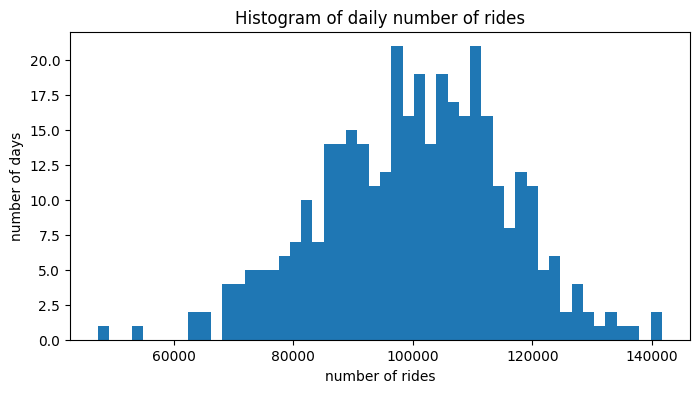

In [124]:
# plot target variable (daily number of rides): histogram of values

import matplotlib.pyplot as plt

pandas_df = dataset.to_pandas()
plt.figure(figsize=(8, 4))
plt.hist(pandas_df["total_rides"], bins=50)
plt.xlabel("number of rides")
plt.ylabel("number of days")
plt.title("Histogram of daily number of rides")
plt.show()

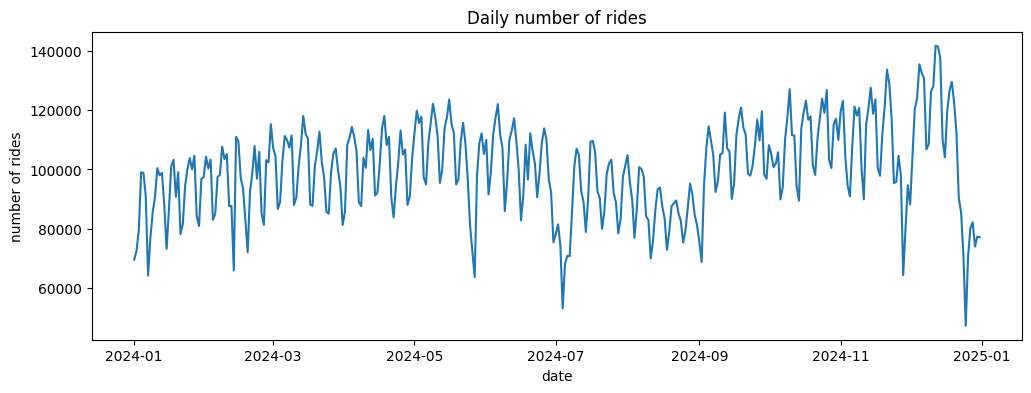

In [125]:
# plot target variable (daily number of rides): line plot, date vs number of rides (remember to sort by date)

pandas_df = dataset.sort("date").to_pandas()

plt.figure(figsize=(12, 4))
plt.plot(pandas_df["date"], pandas_df["total_rides"])
plt.xlabel("date")
plt.ylabel("number of rides")
plt.title("Daily number of rides")
plt.show()